In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [ ]:
pip list

# Часть 1. EDA

* Выберите любой интересующий вас датасет по классификации или регрессии (можно взять из репозитория https://archive.ics.uci.edu/ml/datasets.php, еще неплохие и востребованные на практике варианты - предсказание оттока пользователей https://www.kaggle.com/blastchar/telco-customer-churn или предсказание Customer Livetime Value (CLV или LTV) - https://www.kaggle.com/pankajjsh06/ibm-watson-marketing-customer-value-data
* По выбранному датасету проведите EDA, познакомьтесь с признаками, посмотрите зависимости и т.д.


In [ ]:
df_raw_path = "data/raw/telecom_churn_dataset.csv"
df_raw = pd.read_csv(df_raw_path, sep=",", encoding="utf-8")
df_raw.head(2)

,customer_id,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,...,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn
0,CUST-000001,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1 GB,...,14,5,21,6,1,1168.44,22132.63,Net Banking,Yes,No
1,CUST-000002,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,5 GB,...,82,49,54,10,5,726.35,44364.05,Debit Card,No,No


## Знакомство с данными

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             50000 non-null  str    
 1   gender                  50000 non-null  str    
 2   age                     50000 non-null  int64  
 3   senior_citizen          50000 non-null  int64  
 4   state                   50000 non-null  str    
 5   city_tier               50000 non-null  str    
 6   tenure_months           50000 non-null  int64  
 7   contract_type           50000 non-null  str    
 8   plan_type               50000 non-null  str    
 9   data_plan               50000 non-null  str    
 10  international_plan      50000 non-null  str    
 11  voicemail_plan          50000 non-null  str    
 12  multiple_lines          50000 non-null  str    
 13  online_security         50000 non-null  str    
 14  online_backup           50000 non-null  str    
 

In [3]:
df_cat_raw = df_raw.select_dtypes(include=["str", "object"])

cols_categ = df_cat_raw.columns
print(len(cols_categ))
print(cols_categ)

19
Index(['customer_id', 'gender', 'state', 'city_tier', 'contract_type',
       'plan_type', 'data_plan', 'international_plan', 'voicemail_plan',
       'multiple_lines', 'online_security', 'online_backup',
       'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
       'payment_method', 'paperless_billing', 'churn'],
      dtype='str')


In [4]:
df_num_raw = df_raw.select_dtypes(include="number")
cols_num = df_num_raw.columns
print(len(cols_num))
print(cols_num)

15
Index(['age', 'senior_citizen', 'tenure_months', 'data_usage_gb',
       'total_day_minutes', 'total_eve_minutes', 'total_night_minutes',
       'total_intl_minutes', 'total_day_calls', 'total_eve_calls',
       'total_night_calls', 'total_intl_calls', 'customer_service_calls',
       'monthly_charges', 'total_charges'],
      dtype='str')


In [6]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,50000.0,46.536000,16.658451,18.00,32.0000,47.000,61.0000,75.00
senior_citizen,50000.0,0.274200,0.446115,0.00,0.0000,0.000,1.0000,1.00
tenure_months,50000.0,36.409360,20.777430,1.00,18.0000,36.000,54.0000,72.00
data_usage_gb,50000.0,5.234166,7.972320,0.00,0.9000,2.020,4.9700,35.00
total_day_minutes,50000.0,200.865686,115.285594,0.00,100.8000,202.100,301.0000,400.00
total_eve_minutes,50000.0,175.100128,101.133348,0.00,87.5000,175.500,262.6000,350.00
total_night_minutes,50000.0,150.600006,86.660405,0.00,75.7000,151.000,225.6000,300.00
total_intl_minutes,50000.0,9.486040,12.313675,0.00,2.9000,5.900,8.9000,60.00
total_day_calls,50000.0,74.806020,43.603359,0.00,37.0000,75.000,113.0000,150.00
total_eve_calls,50000.0,59.273520,34.643773,0.00,29.0000,59.000,89.0000,119.00


In [7]:
df_raw.describe(include=["str", "object"]).T

,count,unique,top,freq
customer_id,50000,50000,CUST-000001,1
gender,50000,2,Male,25608
state,50000,15,Maharashtra,7005
city_tier,50000,3,Tier 2,17778
contract_type,50000,3,Month-to-Month,27475
plan_type,50000,2,Postpaid,28819
data_plan,50000,5,5 GB,12666
international_plan,50000,2,No,41073
voicemail_plan,50000,2,No,35181
multiple_lines,50000,3,No,24898


пропуски:

In [8]:
df_raw.isna().values.any()

np.False_

In [9]:
for col in cols_categ:
    print(f"\n--- Колонка: {col} ---")
    print(df_raw[col].value_counts().tail(5)) # топ 5 более редких значений


--- Колонка: customer_id ---
customer_id
CUST-049996    1
CUST-049997    1
CUST-049998    1
CUST-049999    1
CUST-050000    1
Name: count, dtype: int64

--- Колонка: gender ---
gender
Male      25608
Female    24392
Name: count, dtype: int64

--- Колонка: state ---
state
Madhya Pradesh    2045
Andhra Pradesh    2036
Punjab            1507
Haryana           1464
Bihar             1442
Name: count, dtype: int64

--- Колонка: city_tier ---
city_tier
Tier 2    17778
Tier 3    16530
Tier 1    15692
Name: count, dtype: int64

--- Колонка: contract_type ---
contract_type
Month-to-Month    27475
One Year          12571
Two Year           9954
Name: count, dtype: int64

--- Колонка: plan_type ---
plan_type
Postpaid    28819
Prepaid     21181
Name: count, dtype: int64

--- Колонка: data_plan ---
data_plan
5 GB            12666
2 GB            12386
1 GB            10023
Unlimited        9922
No Data Plan     5003
Name: count, dtype: int64

--- Колонка: international_plan ---
international_plan


**дубликаты:**

In [11]:
df_raw.duplicated().sum()

np.int64(0)

**фильтрация строк с месячной оплатой больше, чем суммарной оплатой**

describe() показал странное отношение: min monthly_charges = 200.03 при min total_charges = 157.05

In [12]:
wiered_charges = df_raw[df_raw["monthly_charges"] >
       df_raw["total_charges"]]
wiered_charges.head(7)

,customer_id,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,...,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn
4,CUST-000005,Male,43,0,Kerala,Tier 3,1,Two Year,Postpaid,No Data Plan,...,3,0,63,8,2,803.61,767.07,Net Banking,Yes,No
109,CUST-000110,Male,47,0,Gujarat,Tier 3,1,Month-to-Month,Postpaid,5 GB,...,130,10,31,6,7,1109.46,1046.07,UPI,Yes,Yes
183,CUST-000184,Female,20,0,Tamil Nadu,Tier 1,1,One Year,Postpaid,2 GB,...,140,12,45,13,5,552.05,519.93,Net Banking,No,No
218,CUST-000219,Female,32,0,Andhra Pradesh,Tier 2,1,One Year,Prepaid,2 GB,...,24,93,27,6,3,447.91,339.40,Net Banking,Yes,No
458,CUST-000459,Male,59,0,Rajasthan,Tier 3,1,Month-to-Month,Postpaid,Unlimited,...,76,97,70,1,0,730.04,696.82,UPI,Yes,No
604,CUST-000605,Male,48,0,Kerala,Tier 3,1,One Year,Postpaid,Unlimited,...,33,85,72,8,6,1047.79,992.71,Net Banking,Yes,Yes
684,CUST-000685,Female,23,0,Maharashtra,Tier 1,1,One Year,Postpaid,1 GB,...,110,28,99,5,2,593.10,572.81,Credit Card,No,No


**Целевая переменная:**

In [ ]:
df_raw["churn"].value_counts(normalize=True)

churn
No     0.73
Yes    0.27
Name: proportion, dtype: float64

## Распределение признаков

**Числовые признаки:**

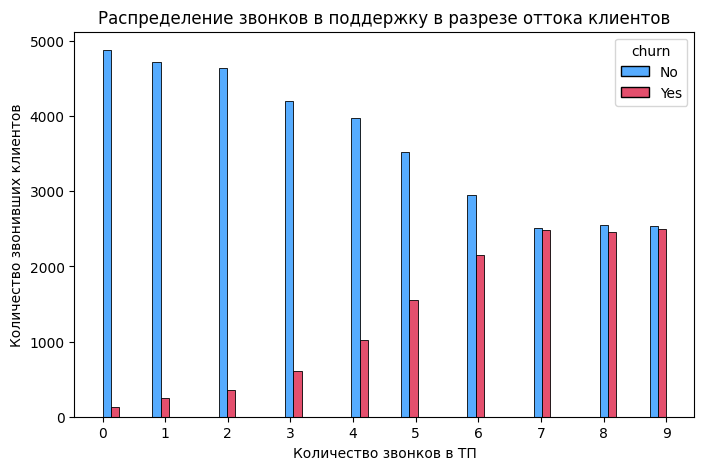

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_raw,
    x="customer_service_calls",
    hue="churn",
    multiple="dodge",
    palette={
        "Yes": "crimson",
        "No": "dodgerblue"
    }
)

plt.xticks(sorted(df_raw["customer_service_calls"].unique()))

plt.title("Распределение звонков в поддержку в разрезе оттока клиентов")
plt.xlabel("Количество звонков в ТП")
plt.ylabel("Количество звонивших клиентов")
plt.show()

- чем чаще клиенты обращается в ТП, тем больше отток клиентов: среди тех, кто звонил от 0 до 3 раз, отток минимальный. Начиная с 7ми образений  количество ушедших клиентов практически сравнивается с количеством оставшихся

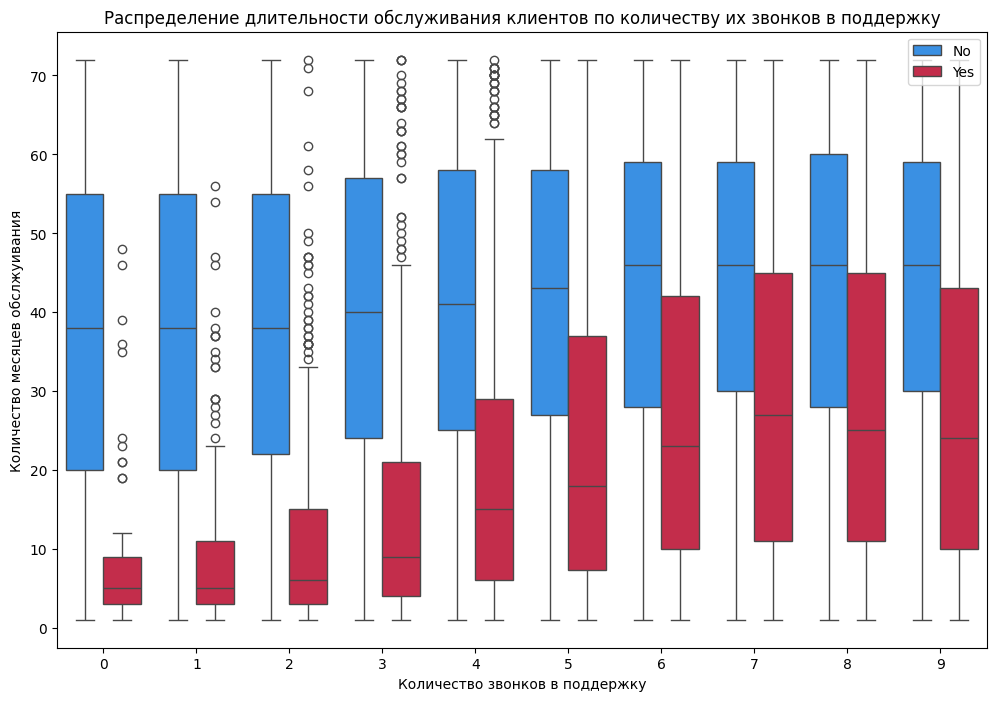

In [113]:
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df_raw, 
    x="customer_service_calls", 
    y="tenure_months", 
    hue="churn",
    palette={
        "Yes": "crimson",
        "No": "dodgerblue"
    }
)

plt.legend(loc="upper right")

plt.title("Распределение длительности обслуживания клиентов по количеству их звонков в поддержку")
plt.xlabel("Количество звонков в поддержку")
plt.ylabel("Количество месяцев обслжуивания")
plt.show()


наблюдается тенденция, что чем больше звонков в ТП, тем больше вероятность ухода клиента, даже если он является клинетом длительный срок:
- для уходящих клиентов churn=Yes наблюдается тренд:  
    - 0-2 обращения в поддержку: уходят в основном клиенты, которых провайдер обслуживает около года. Выбросы подтверждают, что клиенты с долгим сроком обслуживания - скорее исключение из правил.
    - 3-5 обращений в поддержку: начинают узодить клиенты, обслуживаемые в районе 10-20 месяцев. Выбросы подтверждают, что клиенты с более высокой продолжительностью обслуживания - редкие одиночные случаи на фоне общей тенденции клиенткого поведения.
    - 6-9 звонков: медиана ушедших клиентов сдвигается в район 25-27 месяцев обслуживания.
- для лояльных клиентов churn=No (остающихся с провадром), не наблюдается связь между количеством оьращений в ТП и длительностью обслуживания. Медианное время обслуживания таких клиентов - около 40 месяцев (3,5 года) независимо от количества звонков в ТП

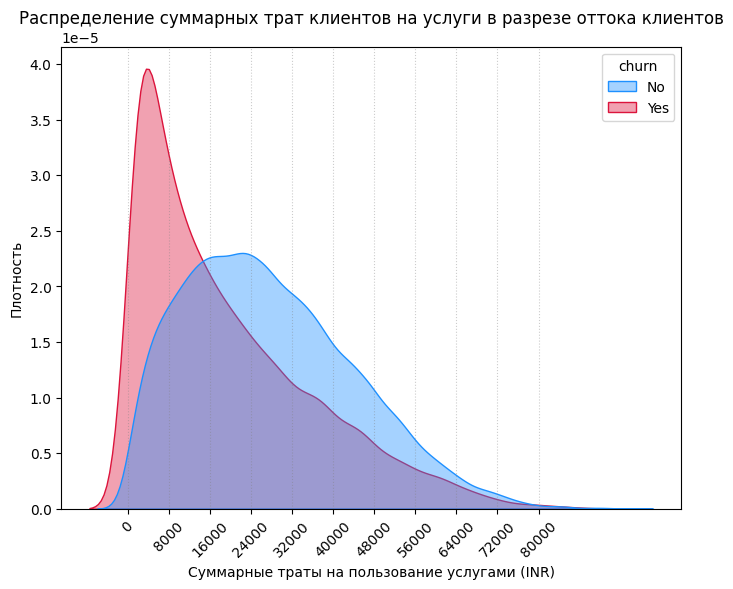

In [ ]:
plt.figure(figsize=(8, 6))
sns.kdeplot(
    data=df_raw,
    x="total_charges", 
    hue="churn",
    fill=True,
    common_norm=False,
    palette={
        "Yes": "crimson",
        "No": "dodgerblue"
    },
    alpha=0.4
)

ticks = np.arange(0, 80_001, 8_000)
plt.xticks(ticks, rotation=45)
plt.grid(axis="x", color="gray", linestyle=":", alpha=0.4)

plt.title("Распределение суммарных трат клиентов на услуги в разрезе оттока клиентов")
plt.xlabel("Суммарные траты на пользование услугами (INR)")
plt.ylabel("Плотность")
plt.show()

ушедшие клтиенты churn=Yes: у графика явно выраженная асимметрия, скошен вправо. Ярко выражен пик
- критическая зона "денежного оттока" - первое время обслуживания, т.е. клиенты уходят, не успев потратить большую сумму денег на услуги (пик в районе 4000 рупий)
- клиенты, суммарно принесшие провайдеру более 24000 рупий - редкое явление

оставшиеся клиенты churn=No: график более пологий
- среди тех, которые остаются с провайдером, доля клиентов со средними и высокими суммарными тратами (от 16000 до 48000 рупий) выше, чем у ушедших клиентов

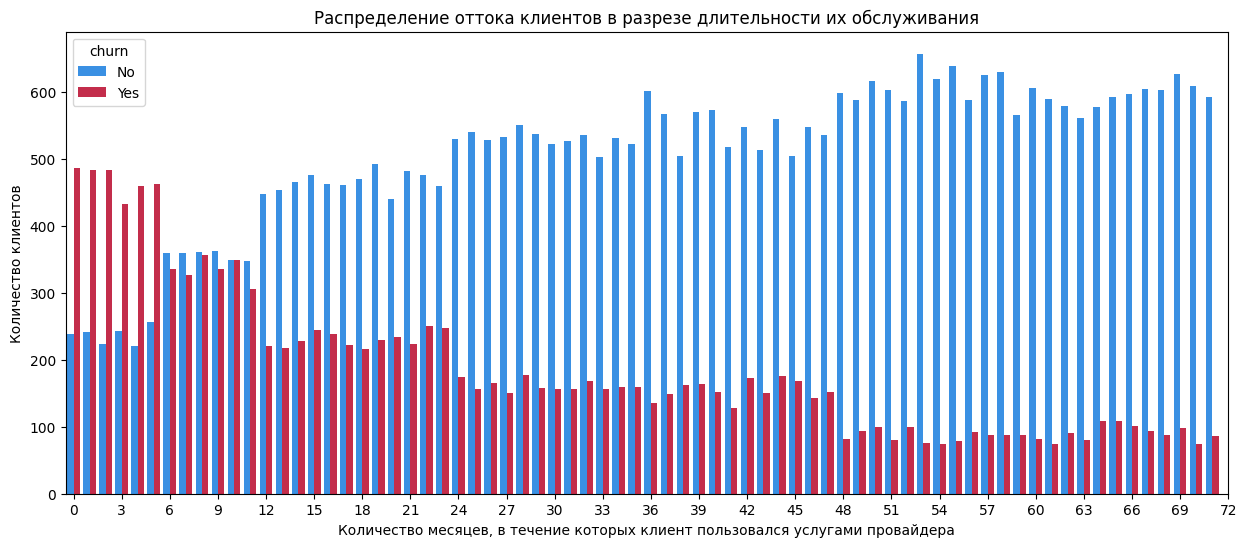

In [104]:
plt.figure(figsize=(15, 6))

sns.countplot(
    data=df_raw,
    x="tenure_months",
    hue="churn",
    palette={
        "Yes": "crimson",
        "No": "dodgerblue"
    }
)

ticks = range(0, 73, 3)
plt.xticks(ticks=ticks, labels=ticks)

plt.title("Распределение оттока клиентов в разрезе длительности их обслуживания")
plt.xlabel("Количество месяцев, в течение которых клиент пользовался услугами провайдера")
plt.ylabel("Количество клиентов")
plt.show()

отчетливо наблюдаются 3 фазы:
- максимальный оттук клиентов - в первые 6 месяцев пользования услугами. Это объясняет пик на графике плотности распредления - такие клиенты суммарно тратят (total_charges) меньше, чем постоянные пользователи
- период с 6 до 12 месяцев - переломный. В этот период отток клиентов замедляется относительно первого полугодия пользования сервисом
- период с 12ти месяцев - основной стаблиный источник дохода. Возврастает лояльность клиента, в уровень оттока значительно ниже, чем в первый год пользования сервисом.

**Категориальные признаки**

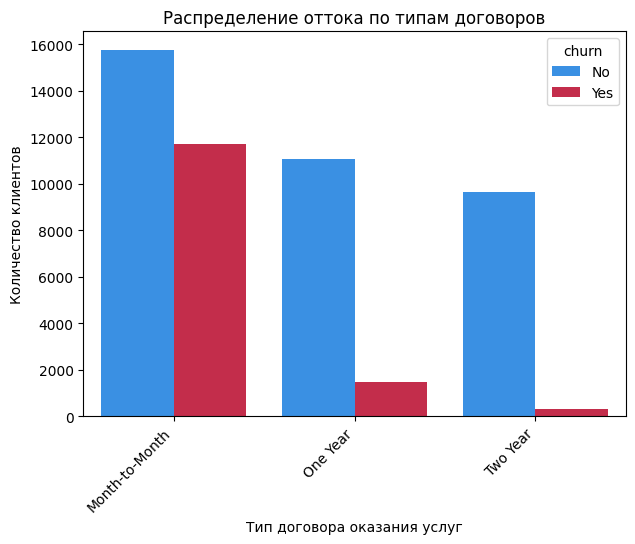

In [145]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_raw,
    x="contract_type",
    hue="churn",
    palette={
        "Yes": "crimson",
        "No": "dodgerblue"
    }
)

plt.title("Распределение оттока по типам договоров")
plt.xlabel("Тип договора оказания услуг")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=45, ha="right")
plt.show()


- значительная доля оттока клиентов приходится на помесячные договоры на оказание услгуг

In [136]:
cols_service = ["international_plan", "voicemail_plan", "multiple_lines", "online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]

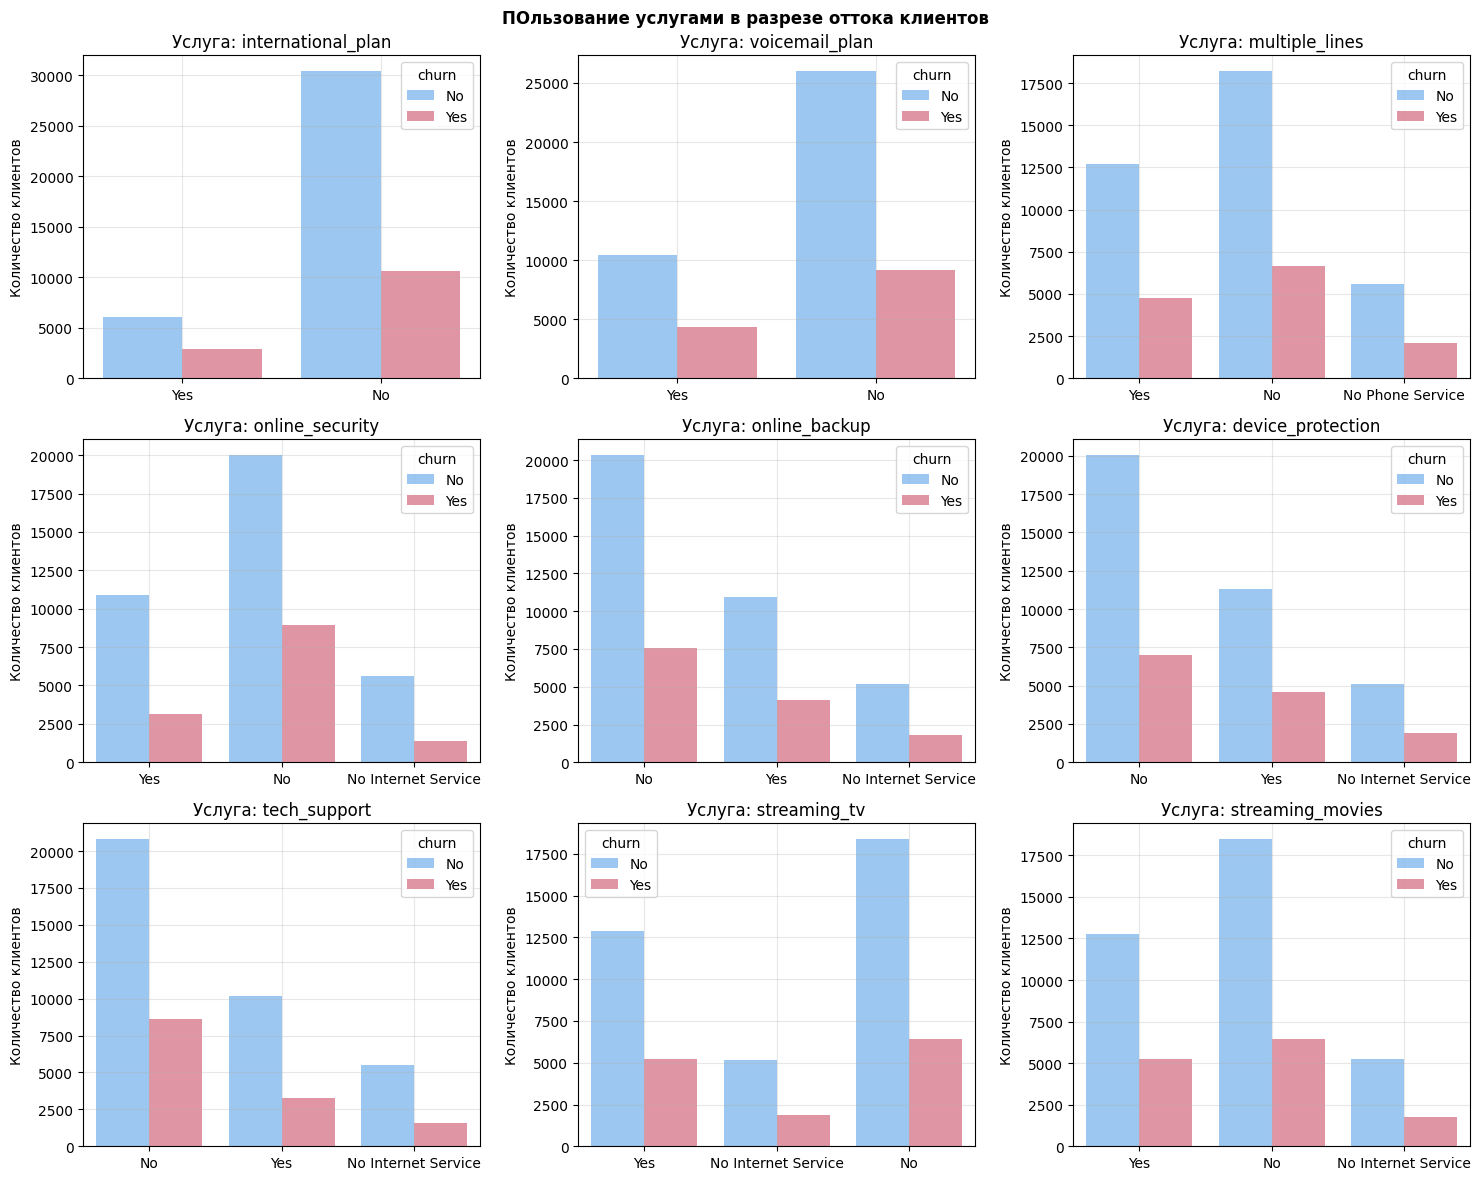

In [152]:
n_cols = 3
n_rows = math.ceil(len(cols_service) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols_service):
    sns.countplot(
        data=df_raw,
        x=col,
        ax=axes[i],
        hue="churn",
        palette={
            "Yes": "crimson",
            "No": "dodgerblue"
        },
        alpha=0.5
    )

    axes[i].set_title(f"Услуга: {col}") 
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Количество клиентов")
    axes[i].grid(True, alpha=0.3)

fig.suptitle("ПОльзование услугами в разрезе оттока клиентов", weight="bold")
plt.tight_layout()
plt.show()

In [ ]:
for col in cols_service:
    print(f"--- Процентный отток для услуги: {col} ---")
    
    ct = pd.crosstab(df_raw[col], df_raw["churn"], normalize="index") * 100
    
    # Округляем для красоты
    print(ct.round(2))
    print("\n")


--- Процентный отток для услуги: international_plan ---
churn                  No    Yes
international_plan              
No                  74.16  25.84
Yes                 67.67  32.33


--- Процентный отток для услуги: voicemail_plan ---
churn              No    Yes
voicemail_plan              
No              74.00  26.00
Yes             70.62  29.38


--- Процентный отток для услуги: multiple_lines ---
churn                No    Yes
multiple_lines                
No                73.23  26.77
No Phone Service  72.90  27.10
Yes               72.72  27.28


--- Процентный отток для услуги: online_security ---
churn                   No    Yes
online_security                  
No                   69.14  30.86
No Internet Service  79.78  20.22
Yes                  77.59  22.41


--- Процентный отток для услуги: online_backup ---
churn                   No    Yes
online_backup                    
No                   72.95  27.05
No Internet Service  73.95  26.05
Yes                

- в среднем уровень оттока по всем услугам держится на одной планке — от 24% до 27%. Сампо по себе наличие/отсутсвие дополнительных услуг не оказывает явного прямого влияния на лояльнсоть клиентов. Что незначительно  выделяется из общего тренда 0 - это international_plan (международная связь, уходят чаще), online_security и tech_support (ИБ и ТП, удерживают клиентов чуть лучше остальных)

## Корреляция признаков

In [14]:
print(df_raw[["total_day_minutes", "total_day_calls"]].corr())


                   total_day_minutes  total_day_calls
total_day_minutes           1.000000         0.000176
total_day_calls             0.000176         1.000000


In [15]:
print(df_raw[["total_eve_minutes", "total_eve_calls"]].corr())


                   total_eve_minutes  total_eve_calls
total_eve_minutes           1.000000         0.003088
total_eve_calls             0.003088         1.000000


In [16]:
print(df_raw[["total_night_minutes", "total_night_calls"]].corr())


                     total_night_minutes  total_night_calls
total_night_minutes             1.000000          -0.006118
total_night_calls              -0.006118           1.000000


In [ ]:
corr_matrix = df_num_raw.corr().abs()

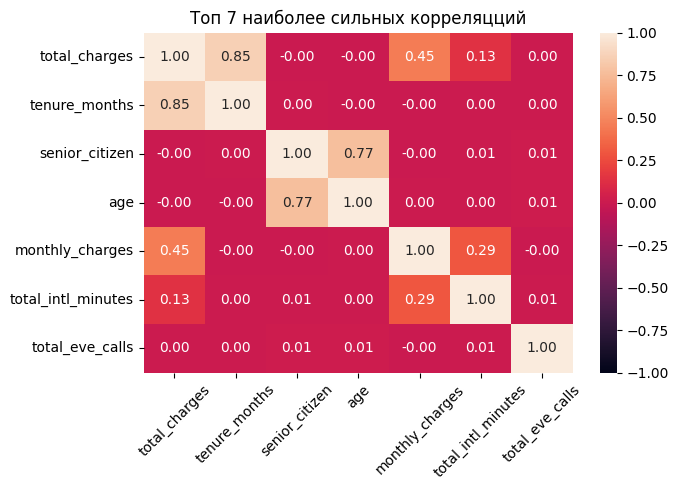

In [ ]:
top_features = corr_matrix.mean().sort_values(ascending=False).index[:7]

plt.figure(figsize=(7,4))
sns.heatmap(
    data=df_num_raw[top_features].corr(),
    annot=True,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.xticks(rotation=45)

plt.title("Топ 7 наиболее сильных корреляцций")
plt.tight_layout()
plt.show()

- корреляция боее 85% - total_charges и tenure_months
- почему-то слабая корреляция между total_charges и monthly_charges

**ИТОГО**
- привести целевую переменную в бинарный вид
- закодировать категориальные переменные 
- использовать стратификацию из-за небольшого дисбаланса классов
- выкинуть лишние пеерменные
- добавить переменные

# Часть 2. Preprocessing & Feature Engineering

* Хотя цель этого задания - посмотреть на работу алгоритмов, тем не менее пропускать препроцессинг нельзя :)
* Так что переведите категориальные переменные в уникальные лейблы при помощи LabelEncoder, попробуйте добавить новые переменные и выкинуть лишние и, наконец, разбейте данные на train-test.

**генерация и отбор признаков**

In [5]:
df = pd.read_csv(df_raw_path, sep=",", encoding="utf-8")
df.head(3)

NameError: name 'df_raw_path' is not defined

In [ ]:
df = df.drop(["customer_id"], axis=1)
df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn
0,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1 GB,Yes,...,14,5,21,6,1,1168.44,22132.63,Net Banking,Yes,No
1,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,5 GB,Yes,...,82,49,54,10,5,726.35,44364.05,Debit Card,No,No
2,Female,23,0,Rajasthan,Tier 3,28,One Year,Postpaid,5 GB,No,...,17,83,88,4,1,430.73,12100.16,Net Banking,Yes,No


In [ ]:
def avg_duration_calculation(minites: pd.Series, calls: pd.Series):
    avg_duration = np.where(
        calls > 0,
        minites / calls,
        0
    )
    return avg_duration

In [ ]:
df["average_day_call_duration"] = avg_duration_calculation(df["total_day_minutes"], df["total_day_minutes"])
df["average_eve_call_duration"] = avg_duration_calculation(df["total_eve_minutes"], df["total_eve_calls"])
df["average_night_call_duration"] = avg_duration_calculation(df["total_night_minutes"], df["total_night_calls"])
df["average_intl_call_duration"] = avg_duration_calculation(df["total_intl_calls"], df["total_intl_calls"])

df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1 GB,Yes,...,1,1168.44,22132.63,Net Banking,Yes,No,1.0,55.520000,11.000000,1.0
1,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,5 GB,Yes,...,5,726.35,44364.05,Debit Card,No,No,1.0,3.259184,0.264815,1.0
2,Female,23,0,Rajasthan,Tier 3,28,One Year,Postpaid,5 GB,No,...,1,430.73,12100.16,Net Banking,Yes,No,1.0,2.478313,2.876136,1.0


**кодирование категориальных признаков**

кодирование целевой переменной

In [ ]:
le = LabelEncoder()
df["churn"] = le.fit_transform(df["churn"])

df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1 GB,Yes,...,1,1168.44,22132.63,Net Banking,Yes,0,1.0,55.520000,11.000000,1.0
1,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,5 GB,Yes,...,5,726.35,44364.05,Debit Card,No,0,1.0,3.259184,0.264815,1.0
2,Female,23,0,Rajasthan,Tier 3,28,One Year,Postpaid,5 GB,No,...,1,430.73,12100.16,Net Banking,Yes,0,1.0,2.478313,2.876136,1.0


кодирование порядковых признаков

In [ ]:
order_features_map = {"No Data Plan": 0, "1 GB": 1, "2 GB": 2, "5 GB": 3, "Unlimited": 4}
df["data_plan"] = df["data_plan"].map(order_features_map)

df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1,Yes,...,1,1168.44,22132.63,Net Banking,Yes,0,1.0,55.520000,11.000000,1.0
1,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,3,Yes,...,5,726.35,44364.05,Debit Card,No,0,1.0,3.259184,0.264815,1.0
2,Female,23,0,Rajasthan,Tier 3,28,One Year,Postpaid,3,No,...,1,430.73,12100.16,Net Banking,Yes,0,1.0,2.478313,2.876136,1.0


кодирование остальных признаков

In [ ]:
print(cols_categ)

Index(['customer_id', 'gender', 'state', 'city_tier', 'contract_type',
       'plan_type', 'data_plan', 'international_plan', 'voicemail_plan',
       'multiple_lines', 'online_security', 'online_backup',
       'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
       'payment_method', 'paperless_billing', 'churn'],
      dtype='str')


In [ ]:
cat_features = [
    'gender', 'state', 'city_tier', 'contract_type',
    'plan_type', 'international_plan', 'voicemail_plan',
    'multiple_lines', 'online_security', 'online_backup',
    'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
    'payment_method', 'paperless_billing'
]
oe = OrdinalEncoder(dtype=int)

df[cat_features] = oe.fit_transform(df[cat_features])
df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,1,26,0,0,2,19,0,0,1,1,...,1,1168.44,22132.63,3,1,0,1.0,55.520000,11.000000,1.0
1,0,53,0,11,0,61,1,1,3,1,...,5,726.35,44364.05,2,0,0,1.0,3.259184,0.264815,1.0
2,0,23,0,10,2,28,1,0,3,0,...,1,430.73,12100.16,3,1,0,1.0,2.478313,2.876136,1.0


In [ ]:
df_path = "data/interim/interim_dataset.csv"
df.to_csv(df_path, sep=",", index_label=False)

**разделение фичей и таргета**

In [4]:
X = df.drop(columns=["churn"])
y = df["churn"]

X.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,1,26,0,0,2,19,0,0,1,1,...,6,1,1168.44,22132.63,3,1,1.0,55.520000,11.000000,1.0
1,0,53,0,11,0,61,1,1,3,1,...,10,5,726.35,44364.05,2,0,1.0,3.259184,0.264815,1.0
2,0,23,0,10,2,28,1,0,3,0,...,4,1,430.73,12100.16,3,1,1.0,2.478313,2.876136,1.0


разделение на трейн-тест

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123, stratify=y)

# Часть 3. Who"s the mightiest of them all?

* Постройте 4 варианта градиентного бустинга, используя значения гиперпараметров “из коробки”: реализация из sklearn, XGBoost, CatBoost, LightGBM
* Проверьте качество на отложенной выборке, кто пока лидирует?
* Теперь проведите настройку гиперпараметров моделей на кросс-валидации, можно настраивать только самые основные гиперпараметры - число итераций бустинга, max_features, subsample и т.д.
* Снова проверьте качество уже настроенных моделей. Кто в итоге победил?

In [3]:
df_path = "data/interim/interim_dataset.csv"
df = pd.read_csv(df_path, sep=",", encoding="utf-8")

df.head(3)

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn,average_day_call_duration,average_eve_call_duration,average_night_call_duration,average_intl_call_duration
0,1,26,0,0,2,19,0,0,1,1,...,1,1168.44,22132.63,3,1,0,1.0,55.520000,11.000000,1.0
1,0,53,0,11,0,61,1,1,3,1,...,5,726.35,44364.05,2,0,0,1.0,3.259184,0.264815,1.0
2,0,23,0,10,2,28,1,0,3,0,...,1,430.73,12100.16,3,1,0,1.0,2.478313,2.876136,1.0


In [ ]:
models = {
    "Sklearn HGB": HistGradientBoostingClassifier(random_state=123),
    "XGBoost": XGBClassifier(random_state=123, eval_metric="logloss"),
    "CatBoost": CatBoostClassifier(random_state=123, verbose=0),
    "LightGBM": LGBMClassifier(random_state=123, verbose=-1)
}

res_baseline = {}
res_test = {}

print("Обучение моделей из коробки")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)

    roc_auc_baseline = roc_auc_score(y_test, y_pred_proba[:,1])

    res_baseline[name] = roc_auc_baseline
    print(f"{name} рок-аук: {roc_auc_baseline:.3f}")

# лидер среди ВСЕХ моделей - модель с самым высоким роккуком на тесте
winner_baseline = max(res_baseline, key=lambda m:res_baseline[m])
print(f"\nЛидер бейслайна на тесте: {winner_baseline} с roc_auc={res_baseline[winner_baseline]:.3f}")

Обучение моделей из коробки
Sklearn HGB рок-аук: 0.962
XGBoost рок-аук: 0.960
CatBoost рок-аук: 0.968
LightGBM рок-аук: 0.963

Лидер бейслайна на тесте: CatBoost с roc_auc=0.968


In [8]:
# проведите настройку гиперпараметров моделей на кросс-валидации
param_grids = {
    "Sklearn HGB": {
        "max_iter": [50, 100, 150],
        "max_depth": [3, 5, 8],
        "learning_rate": [0.01, 0.05, 0.1]
    },
    "XGBoost": {
        "n_estimators": [50, 100, 150],
        "max_depth": [3, 5, 8],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.7, 0.8, 1.0]
    },
    "LightGBM": {
        "n_estimators": [50, 100, 150],
        "max_depth": [3, 5, 8],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.7, 0.8, 1.0]
    },
    "CatBoost": {
        "iterations": [50, 100, 150],
        "depth": [3, 5, 8],
        "learning_rate": [0.01, 0.05, 0.1]
    }
}

In [15]:
%%time

res_gs_tuned = {}

print("Обучение с гиперпараметрами GridSearchCV")
for name, model in models.items():
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=7,
        scoring='roc_auc',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

    y_pred_proba = best_model.predict_proba(X_test)
    roc_auc_tuned = roc_auc_score(y_test, y_pred_proba[:,1])
    
    res_gs_tuned[name] = roc_auc_tuned

    # результаты прогона моделей на фолдах тренировочной выборки
    #Нна основе этих средних результатов GridSearchCV выберает лучшие параметры
    print(f"Луший средний рок-аук на кросс валидации для {name}: {grid_search.best_score_:.3f}")
    print(f"Лучшие параметры для этого рок-аука: {grid_search.best_params_}")

    # результат лучшей модели на тесте- модель обучилась на всем X_train
    #с параметрами best_params_ и применила их к X_test:
    print(f"Лучший {name} на тесте: {grid_search.scoring}={res_gs_tuned[name]:.3f}\n")

# лидер среди ВСЕХ настроенных моделей - модель с самым высоким роккуком на тесте
winner_gs = max(res_gs_tuned, key=lambda m: res_gs_tuned[m])
print(f"Новый лидер (после тюннинга) на тесте: {winner_gs} с {grid_search.scoring}={res_gs_tuned[winner_gs]:.3f}")

Обучение с гиперпараметрами GridSearchCV
Луший средний рок-аук на кросс валидации для Sklearn HGB: 0.962
Лучшие параметры для этого рок-аука: {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100}
Лучший Sklearn HGB на тесте: roc_auc=0.967

Луший средний рок-аук на кросс валидации для XGBoost: 0.963
Лучшие параметры для этого рок-аука: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.7}
Лучший XGBoost на тесте: roc_auc=0.968

Луший средний рок-аук на кросс валидации для CatBoost: 0.966
Лучшие параметры для этого рок-аука: {'depth': 3, 'iterations': 100, 'learning_rate': 0.1}
Лучший CatBoost на тесте: roc_auc=0.970

Луший средний рок-аук на кросс валидации для LightGBM: 0.962
Лучшие параметры для этого рок-аука: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.7}
Лучший LightGBM на тесте: roc_auc=0.967

Новый лидер (после тюннинга) на тесте: CatBoost с roc_auc=0.970
CPU times: total: 2min 45s
Wall time: 1min 39s


In [17]:
%%time

res_rs_tuned = {}

print("Обучение с гиперпараметрами RandomizedSearchCV")
for name, model in models.items():
    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[name],
        cv=7,
        scoring='roc_auc',
        n_jobs=-1
    )

    random_search.fit(X_train, y_train)
    best_model = random_search.best_estimator_

    y_pred_proba = best_model.predict_proba(X_test)
    roc_auc_tuned = roc_auc_score(y_test, y_pred_proba[:,1])

    res_rs_tuned[name] = roc_auc_tuned

    print(f"Луший средний рок-аук на кросс валидации для {name}: {random_search.best_score_:.3f}")
    print(f"Лучшие параметры: {random_search.best_params_}")

    print(f"Лучший {name} на тесте: {random_search.scoring}={res_rs_tuned[name]:.3f}\n")


winner_rs = max(res_rs_tuned, key=lambda m: res_rs_tuned[m])
print(f"Новый лидер (после тюннинга) на тесте: {winner_rs} с {random_search.scoring} {res_rs_tuned[winner_rs]:.3f}\n")

Обучение с гиперпараметрами RandomizedSearchCV
Луший средний рок-аук на кросс валидации для Sklearn HGB: 0.960
Лучшие параметры: {'max_iter': 50, 'max_depth': 3, 'learning_rate': 0.1}
Лучший Sklearn HGB на тесте: roc_auc=0.964

Луший средний рок-аук на кросс валидации для XGBoost: 0.962
Лучшие параметры: {'subsample': 0.7, 'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.05}
Лучший XGBoost на тесте: roc_auc=0.967

Луший средний рок-аук на кросс валидации для CatBoost: 0.966
Лучшие параметры: {'learning_rate': 0.1, 'iterations': 100, 'depth': 3}
Лучший CatBoost на тесте: roc_auc=0.970

Луший средний рок-аук на кросс валидации для LightGBM: 0.962
Лучшие параметры: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}
Лучший LightGBM на тесте: roc_auc=0.967

Новый лидер (после тюннинга) на тесте: CatBoost с roc_auc 0.970

CPU times: total: 23.2 s
Wall time: 19.5 s


In [19]:
df_comparison = pd.DataFrame({
    "Baseline roc-auc": res_baseline,
    "GridSearchCV roc-auc": res_gs_tuned,
    "RandomizedSearchCV roc-auc": res_rs_tuned
})    
df_comparison["Разница GridSearchCV"] = df_comparison["GridSearchCV roc-auc"] - df_comparison["Baseline roc-auc"]
df_comparison["Разница RandomizedSearchCV"] = df_comparison["RandomizedSearchCV roc-auc"] - df_comparison["Baseline roc-auc"]

df_comparison

,Baseline roc-auc,GridSearchCV roc-auc,RandomizedSearchCV roc-auc,Разница GridSearchCV,Разница RandomizedSearchCV
Sklearn HGB,0.962242,0.966951,0.963503,0.004709,0.001261
XGBoost,0.960051,0.967543,0.967387,0.007492,0.007336
CatBoost,0.967894,0.969764,0.969764,0.001870,0.001870
LightGBM,0.962568,0.966634,0.967461,0.004066,0.004893


**Итого:**
- лидером стал CatBoost: он показал самый высокий результат как из коробки, иак м прсле настройки гиперараметров на кросс валидации.
- кросс валидация на 7 фолдах обеспечила незначительный прирос качества всех моделей относительно бейслайна. БОльший прогресс в качестве показал XGBoost
- эксперемент по сравнению GridSearchCV  и RandomizedSearchCV показал, что случайный поиск, отработав в 2 раза быстрее, выдал качество, уступающее сетке на тысячных долях рок-аука